# EDA — FLEX (PSI-69, Flame Extinguishment Experiment)

Exploratory analysis of the FLEX experiment table (NASA PSI, CC0). Droplet combustion in microgravity with varying oxygen, pressure and diluents (N2, CO2, He).

Rules (see team docs): nothing is deleted or imputed here; every data decision is logged in `DECISIONES_DATOS.md`.

**Order:** 1) load the PSI table; 2) incorporate and validate the NASA report (before any analysis); 3) univariate analysis; 4) odd values; 5) missing values. Each topic: analysis → conclusions → discussion with Lautaro → decision → action.

## 1. Load and provenance

In [1]:
import pandas as pd, numpy as np, hashlib, pathlib
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

SRC = pathlib.Path('../Backend/psi-combustion/tablas_experimentales/PSI-69_Experimental table_FLEX.csv')
raw_bytes = SRC.read_bytes()
print('file:', SRC.name)
print('size:', len(raw_bytes), 'bytes | sha256:', hashlib.sha256(raw_bytes).hexdigest()[:16])
for enc in ('utf-8', 'cp1252'):
    try:
        raw_bytes.decode(enc); print('decodes as', enc); break
    except UnicodeDecodeError:
        print('NOT', enc)

file: PSI-69_Experimental table_FLEX.csv
size: 24776 bytes | sha256: 37c88ce8ae9391b7
NOT utf-8
decodes as cp1252


In [2]:
# Raw load: everything as text, nothing converted (L0 view)
raw = pd.read_csv(SRC, encoding='cp1252', dtype=str, keep_default_na=False)
print('rows:', raw.shape[0], '| columns:', raw.shape[1])
for i, c in enumerate(raw.columns):
    print(f'{i:2d} {c!r}')

rows: 274 | columns: 15
 0 'FLEX Test #'
 1 'FLEX Identifier'
 2 'Test Date'
 3 'Test GMT'
 4 'Fuel'
 5 'Ambient pressure; mmHg'
 6 'O initial ambient composition; mole fraction'
 7 'N initial ambient composition; mole fraction'
 8 'CO initial ambient composition; mole fraction'
 9 'He initial ambient composition; mole fraction'
10 'Droplet initial diameter; mm'
11 'Visible flame extinction diameter; mm'
12 'Burning rate; mm'
13 'Burn time; s'
14 'Test end'


In [3]:
raw.head(8)

,FLEX Test #,FLEX Identifier,Test Date,Test GMT,Fuel,Ambient pressure; mmHg,O initial ambient composition; mole fraction,N initial ambient composition; mole fraction,CO initial ambient composition; mole fraction,He initial ambient composition; mole fraction,Droplet initial diameter; mm,Visible flame extinction diameter; mm,Burning rate; mm,Burn time; s,Test end
0,1,20CAL08,3/5/2009,17:22:03,Methanol,757.7,0.21,0.79,0,0,1.69,0.89,0.52,4.3,Disruption
1,2,20CAL10,3/5/2009,19:20:06,Methanol,762,0.21,0.79,0,0,1.86,0.94,0.6,5,Extinction
2,3,20CAL12,3/5/2009,21:17:46,Methanol,764.2,0.21,0.79,0,0,1.61,0.92,0.58,3.2,Extinction
3,4,30CAL02,3/31/2009,17:16:18,Methanol,760,0.21,0.79,0,0,2.06,,0.6,7.64,Extinction
4,5,30CAL03,3/31/2009,19:00:48,Methanol,760,0.21,0.79,0,0,1.92,0.81,0.48,6.34,Extinction
5,6,40CAL01,3/31/2009,20:05:49,Methanol,760,0.21,0.79,0,0,2.54,1.53,0.51,9.6,Extinction
6,7,20CAL13,4/10/2009,13:26:11,Heptane,761.3,0.21,0.79,0,0,1.87,,0.67,5.3,Disruption
7,8,30CAL06,4/10/2009,18:07:15,Heptane,762.4,0.21,0.79,0,0,2.95,,0.79,14.8,Disruption


In [4]:
# What kind of values does each column hold? (numeric-parsable, empty, other text)
def kind(s):
    s = s.str.strip()
    num = pd.to_numeric(s, errors='coerce')
    empty = s.eq('')
    return pd.Series({'numeric': int(num.notna().sum()), 'empty': int(empty.sum()),
                      'non_numeric_text': int((num.isna() & ~empty).sum()),
                      'unique': s.nunique()})
summary = raw.apply(kind).T
summary

,numeric,empty,non_numeric_text,unique
FLEX Test #,274,0,0,274
FLEX Identifier,0,0,274,273
Test Date,0,0,274,80
Test GMT,0,1,273,270
Fuel,0,0,274,2
Ambient pressure; mmHg,274,0,0,183
O initial ambient composition; mole fraction,274,0,0,15
N initial ambient composition; mole fraction,274,0,0,33
CO initial ambient composition; mole fraction,274,0,0,14
He initial ambient composition; mole fraction,274,0,0,10


In [5]:
# Non-numeric values found in columns that should be numeric
numeric_like = [c for c in raw.columns if summary.loc[c,'numeric'] > 0.5*len(raw)]
for c in numeric_like:
    s = raw[c].str.strip()
    bad = s[pd.to_numeric(s, errors='coerce').isna() & s.ne('')]
    if len(bad):
        print(f'{c!r}: {bad.value_counts().to_dict()}')

'Droplet initial diameter; mm': {'–': 6}
'Visible flame extinction diameter; mm': {'–': 28}
'Burn time; s': {'~6': 1, '~9': 1}


## 2. Sources: NASA report, validation and incorporation

Done **before** the exploratory analysis, so that every later section works on the complete, validated data (276 tests, with the report's per-test information).

### 2.1 What the source documentation says

Source: NASA/TP-2015-216046, *Detailed Results From the Flame Extinguishment Experiment (FLEX), March 2009 to December 2011* (Dietrich et al., 2015, NTRS 20150023456). Its Table IX is the origin of this CSV.

- **Burning rate is in mm²/s** (d-squared constant), not mm as the CSV header says.
- **Visible flame extinction diameter:** droplet diameter when the visible flame went out. **'–' (or empty in the CSV) = no extinction at a finite size** (droplet burned to completion, or a disruption ended the test), or the droplet left the camera view and could not be extrapolated. **0 is not defined**; in NASA's table it only appears in `Completion`/`Disruption` tests → read as 'no droplet left'.
- **`Disruption`** = disruptive extinction. NASA states it was **probably caused by a contaminant** for methanol, and *may* be for heptane (§5). It is partly an experimental artifact, not a clean physical outcome → it must not be read as an effect of oxygen.
- **0.70 atm / 30% O2** = ISS EVA pre-breathe environment and the maximum proposed O2 for future exploration vehicles.
- Test 114 (pressure 0) and the 70/73 duplicate already exist in NASA's table. The test matrix (Table V) says FLEX-070 was a 1.30 mm droplet: both rows are FLEX-073; FLEX-070's real data are missing.
- **The CSV `FLEX Test #` is not the official FLEX number** after row 155 (120 rows differ). Stable key: `flex_id` + official number.
- The report has variables the CSV lacks: **fiber-supported vs free droplet**, water vapor and fuel vapor fractions, per-test notes.

### 2.2 Parse values (raw kept, special values flagged — nothing imputed)

### 2.1 Parse values (raw kept, special values flagged — nothing imputed)
- `–` (cp1252 0x96) = no data → NaN + flag `missing`
- `~x` = approximate → value x + flag `approx`
- Pressure converted mmHg → kPa (1 mmHg = 0.133322 kPa) and atm

In [6]:
COLS = {
 'FLEX Test #':'test_no', 'FLEX Identifier':'flex_id', 'Test Date':'date_raw', 'Test GMT':'gmt_raw', 'Fuel':'fuel',
 'Ambient pressure; mmHg':'pressure_mmhg', 'O initial ambient composition; mole fraction':'o2_frac',
 'N initial ambient composition; mole fraction':'n2_frac', 'CO initial ambient composition; mole fraction':'co2_frac',
 'He initial ambient composition; mole fraction':'he_frac', 'Droplet initial diameter; mm':'d0_mm',
 'Visible flame extinction diameter; mm':'dext_mm', 'Burning rate; mm':'burn_rate', 'Burn time; s':'burn_time_s', 'Test end':'test_end'}
df = raw.rename(columns=COLS).copy()

def parse_number(s):
    s = s.str.strip()
    flag = pd.Series('', index=s.index)
    flag[s.eq('–')] = 'missing'
    flag[s.eq('')] = 'empty'
    approx = s.str.startswith('~')
    flag[approx] = 'approx'
    val = pd.to_numeric(s.str.lstrip('~'), errors='coerce')
    return val, flag

NUM = ['pressure_mmhg','o2_frac','n2_frac','co2_frac','he_frac','d0_mm','dext_mm','burn_rate','burn_time_s']
for c in NUM:
    df[c + '_raw'] = df[c]
    df[c], df[c + '_flag'] = parse_number(df[c])

df['pressure_kpa'] = df['pressure_mmhg'] * 0.133322
df['pressure_atm'] = df['pressure_mmhg'] / 760
df['test_date'] = pd.to_datetime(df['date_raw'], format='mixed')
for c in NUM:
    vc = df[c + '_flag'].value_counts().drop('', errors='ignore')
    if len(vc): print(c, vc.to_dict())

d0_mm {'empty': 6, 'missing': 6}


dext_mm {'empty': 49, 'missing': 28}
burn_rate {'empty': 16}
burn_time_s {'empty': 6, 'approx': 2}


In [7]:
def atmosphere(r):
    if r.co2_frac > 0 and r.he_frac > 0: return 'CO2+He'
    if r.co2_frac > 0: return 'CO2'
    if r.he_frac > 0: return 'He'
    return 'N2 only'
df['diluent'] = df.apply(atmosphere, axis=1)
print(df['diluent'].value_counts().to_dict())
print(pd.crosstab([df['fuel'], df['diluent']], df['test_end']))

{'CO2': 123, 'N2 only': 101, 'He': 50}
test_end          Completion  Disruption  Extinction
fuel     diluent                                    
Heptane  CO2               3          18          27
         He                6           2          14
         N2 only          10          18          19
Methanol CO2               5           9          61
         He                0           2          26
         N2 only           3          12          39


### 2.3 Validation against NASA Table IX and the two missing tests (DD-017, DD-018, decided by Lautaro)

- `tools/extract_flex_report.py` also extracts NASA's **Table IX** verbatim into `data/extracted/flex_table_ix.csv` (276 rows).
- **DD-017:** where the caption's environment disagrees with the table, the table wins; flag `caption_env_mismatch`.
- **DD-018:** the 2 tests that are in Table IX but missing from the PSI CSV (FLEX-216, FLEX-230) are added, with `source = 'NASA/TP-2015-216046 Table IX'`.

In [8]:
t9 = pd.read_csv('../data/extracted/flex_table_ix.csv', dtype=str)
num_ix = lambda s: pd.to_numeric(s.str.strip().str.lstrip('~').replace({'–': None}), errors='coerce')
# Validate: every CSV value vs. Table IX (excluding the duplicated id)
chk = raw.rename(columns=COLS)[['flex_id','pressure_mmhg','o2_frac','n2_frac','co2_frac','he_frac','d0_mm','dext_mm','burn_rate','burn_time_s','test_end']]
chk = chk.merge(t9, on='flex_id', suffixes=('','_ix'))
chk = chk[~chk['flex_id'].duplicated(keep=False)]
pairs = [('pressure_mmhg','pressure_mmhg_ix'),('o2_frac','o2'),('n2_frac','n2'),('co2_frac','co2'),('he_frac','he'),('d0_mm','d0_mm_ix'),('dext_mm','dext_mm_ix'),('burn_rate','burn_rate_mm2_s'),('burn_time_s','burn_time_s_ix')]
ndiff = 0
for a, b in pairs:
    x = pd.to_numeric(chk[a].str.strip().str.lstrip('~').replace({'–': None}), errors='coerce'); y = num_ix(chk[b])
    ndiff += int((~(np.isclose(x, y) | (x.isna() & y.isna()))).sum())
print('rows compared:', len(chk), '| differing values:', ndiff, '| differing outcomes:', int((chk['test_end'] != chk['test_end_ix']).sum()))

rows compared: 272 | differing values: 0 | differing outcomes: 0


### 2.4 Per-test information from the report (DD-016, decided by Lautaro)

Extracted with `tools/extract_flex_report.py` from NASA/TP-2015-216046, Appendix B (one description per test, Figures 5–280) into `data/extracted/flex_report_tests.csv`, with provenance (official FLEX number, figure, PDF page).
- `support`: free-floating vs fiber-supported droplet (100% coverage).
- Quality flags: the report **mentions** the issue (left camera view, extrapolated diameter, unreliable data, fiber dislodged, oscillation, cool flame, soot). Absence of a mention is not proof of absence → used as information, not as a filter.
- `caption`: verbatim description, citable as evidence.

In [9]:
rep = pd.read_csv('../data/extracted/flex_report_tests.csv')
# Join key: CIR identifier; for the duplicated id (193F001) use the CSV row number, which equals the official number below row 156
dup_ids = rep['flex_id'][rep['flex_id'].duplicated(keep=False)].unique()
df['test_no_int'] = df['test_no'].astype(int)
uni = df[~df['flex_id'].isin(dup_ids)].merge(rep[~rep['flex_id'].isin(dup_ids)], on='flex_id', how='left')
dup = df[df['flex_id'].isin(dup_ids)].merge(rep[rep['flex_id'].isin(dup_ids)], left_on=['flex_id','test_no_int'], right_on=['flex_id','flex_no'], how='left')
df = pd.concat([uni, dup]).sort_values('test_no_int').reset_index(drop=True)
print('rows:', len(df), '| without report info:', df['support'].isna().sum())
print('CSV row number != official FLEX number:', (df['test_no_int'] != df['flex_no']).sum())

rows: 274 | without report info: 0
CSV row number != official FLEX number: 119


In [10]:
# DD-017: flag caption/table environment mismatch (table values are kept)
df['source'] = 'PSI CSV (PSI-69)'
df['caption_env_mismatch'] = ((df['caption_o2_frac'] - df['o2_frac']).abs() > 0.015) | ((df['caption_pressure_atm'] - df['pressure_atm']).abs() > 0.05)
print('caption_env_mismatch:', int(df['caption_env_mismatch'].sum()))

# DD-018: add the 2 tests present in Table IX but missing from the PSI CSV
missing = t9[~t9['flex_id'].isin(df['flex_id'])].copy()
new = pd.DataFrame({'test_no': None, 'flex_id': missing['flex_id'], 'date_raw': missing['date'], 'gmt_raw': missing['gmt'], 'fuel': missing['fuel'], 'test_end': missing['test_end']})
for c_df, c_ix in [('pressure_mmhg','pressure_mmhg'),('o2_frac','o2'),('n2_frac','n2'),('co2_frac','co2'),('he_frac','he'),('d0_mm','d0_mm'),('dext_mm','dext_mm'),('burn_rate','burn_rate_mm2_s'),('burn_time_s','burn_time_s')]:
    new[c_df + '_raw'] = missing[c_ix].values
    new[c_df] = num_ix(missing[c_ix]).values
    new[c_df + '_flag'] = np.where(missing[c_ix].str.strip().eq('–'), 'missing', np.where(missing[c_ix].str.startswith('~'), 'approx', ''))
new['pressure_kpa'] = new['pressure_mmhg'] * 0.133322; new['pressure_atm'] = new['pressure_mmhg'] / 760
new['test_date'] = pd.to_datetime(new['date_raw'], format='mixed')
new['comp_sum'] = new[['o2_frac','n2_frac','co2_frac','he_frac']].sum(axis=1)
new['diluent'] = new.apply(atmosphere, axis=1)
new['duplicate_id'] = False
new['source'] = 'NASA/TP-2015-216046 Table IX'
new = new.merge(rep, on='flex_id', how='left')
new['caption_env_mismatch'] = False
df = pd.concat([df, new], ignore_index=True)
print('FLEX tests now:', len(df), '|', df['source'].value_counts().to_dict())
df.loc[df['source'].str.startswith('NASA'), ['flex_no','flex_id','fuel','pressure_atm','o2_frac','he_frac','d0_mm','dext_mm','burn_rate','test_end','support']]

caption_env_mismatch: 23


FLEX tests now:

 276 | {'PSI CSV (PSI-69)': 274, 'NASA/TP-2015-216046 Table IX': 2}


,flex_no,flex_id,fuel,pressure_atm,o2_frac,he_frac,d0_mm,dext_mm,burn_rate,test_end,support
274,216,N03H201,Heptane,1.008158,0.15,0.00,1.77,0.33,0.47,Completion,free
275,230,H01H103,Heptane,0.995395,0.20,0.05,2.30,NaN,0.58,Disruption,free


In [11]:
# Consistency check: environment stated in the caption vs. CSV values
chk = df.dropna(subset=['caption_o2_frac'])
d_o2 = (chk['caption_o2_frac'] - chk['o2_frac']).abs()
d_p = (chk['caption_pressure_atm'] - chk['pressure_atm']).abs()
print('tests with environment in caption:', len(chk))
print('O2 differs by > 0.015:', int((d_o2 > 0.015).sum()), '| pressure differs by > 0.05 atm:', int((d_p > 0.05).sum()))
chk.loc[(d_o2 > 0.015) | (d_p > 0.05), ['test_no','flex_no','flex_id','o2_frac','caption_o2_frac','pressure_atm','caption_pressure_atm']]

tests with environment in caption: 198
O2 differs by > 0.015: 10 | pressure differs by > 0.05 atm: 13


,test_no,flex_no,flex_id,o2_frac,caption_o2_frac,pressure_atm,caption_pressure_atm
9,10,10,256F002,0.21,0.21,3.052237,3.0
10,11,11,256R001,0.21,0.21,3.051053,3.0
11,12,12,264F003,0.21,0.21,3.052500,3.0
12,13,13,256R002,0.21,0.21,2.729211,3.0
13,14,14,256F007,0.21,0.21,2.704737,3.0
14,15,15,256F008,0.21,0.21,2.719211,3.0
15,16,16,256F009,0.21,0.21,2.726447,3.0
16,17,17,240R003,0.21,0.21,2.033816,3.0
22,23,23,196F002,0.34,0.37,0.712895,0.7
28,29,29,178R001,0.30,0.36,1.009079,1.0


**Result:** the PSI CSV is a faithful copy of NASA's Table IX (0 differing values in 272 comparable tests). FLEX now has **276 tests**: 274 from the PSI CSV + 2 from Table IX, each with `source` provenance.

### 2.5 Findings of the incorporation

- **All 274 CSV tests matched** a report description (276 descriptions; 2 extra tests are discussed below).
- **Support:** 210 free-floating, 64 fiber-supported. Support is associated with the outcome (e.g. methanol: free 109/122 Extinction vs. fiber 17/35) → it is a **confounder** and must enter the model.
- **Cool flames:** mentioned in 54 tests, all heptane, 53 of them `Extinction`. For heptane, the visible (hot) flame often goes out while a cool flame keeps burning → the 'extinction' of the visible flame is not always the end of combustion (FLEX publications discuss this regime).
- **Missing extinction diameter is partly explained by the droplet leaving the camera view:** 49/129 missing when the report mentions it left the view vs. 28/145 otherwise → input for the missingness analysis (step 3).
- **Caption environment vs. table values:** captions give nominal conditions (e.g. '3.0-atm' for tests at 2.0–2.7 atm) and a few contradict the table (FLEX-096: caption 1.0 atm vs. table 0.70; FLEX-181–183: caption 0.7 vs. table 1.0; FLEX-185: caption O2 0.70, a typo). Table values come from chamber records → proposal: keep table values and flag the mismatch; caption environment is not used as data.
- **The PSI CSV is missing 2 tests that exist in NASA's Table IX:** FLEX-216 (N03H201) and FLEX-230 (H01H103), with complete numeric rows. Official numbers 156, 205, 213 and 228 do not exist in the report at all.

## 3. Univariate analysis (276 tests)

### 3.1 Descriptive statistics

In [12]:
num = ['pressure_atm','o2_frac','n2_frac','co2_frac','he_frac','d0_mm','dext_mm','burn_rate','burn_time_s']
desc = df[num].describe(percentiles=[.05,.25,.5,.75,.95]).T
desc['missing'] = df[num].isna().sum()
desc.round(3)

,count,mean,std,min,5%,25%,50%,75%,95%,max,missing
pressure_atm,276.0,0.943,0.361,0.00,0.699,0.706,0.999,1.008,1.015,3.052,0
o2_frac,276.0,0.200,0.048,0.12,0.130,0.170,0.200,0.210,0.300,0.340,0
n2_frac,276.0,0.631,0.176,0.09,0.380,0.520,0.660,0.790,0.860,0.880,0
co2_frac,276.0,0.119,0.174,0.00,0.000,0.000,0.000,0.200,0.450,0.700,0
he_frac,276.0,0.048,0.112,0.00,0.000,0.000,0.000,0.000,0.350,0.450,0
d0_mm,264.0,2.994,0.698,1.10,1.752,2.570,3.010,3.522,4.110,4.670,12
dext_mm,198.0,1.902,1.039,0.00,0.198,1.160,1.760,2.610,3.719,4.600,78
burn_rate,260.0,0.502,0.137,0.05,0.329,0.400,0.500,0.580,0.730,1.060,16
burn_time_s,270.0,11.160,7.559,0.30,1.545,5.325,9.600,15.600,24.795,39.200,6


In [13]:
print(df['fuel'].value_counts().to_dict())
print(df['test_end'].value_counts().to_dict())
print(pd.crosstab(df['fuel'], df['test_end'], margins=True))
print('dates:', df['test_date'].min().date(), '->', df['test_date'].max().date(), '| distinct test days:', df['test_date'].nunique())

{'Methanol': 157, 'Heptane': 119}
{'Extinction': 186, 'Disruption': 62, 'Completion': 28}
test_end  Completion  Disruption  Extinction  All
fuel                                             
Heptane           20          39          60  119
Methanol           8          23         126  157
All               28          62         186  276
dates: 2009-03-05 -> 2011-12-08 | distinct test days: 80


### 3.2 Physical sanity checks

In [14]:
chk = {}
chk['pressure <= 0'] = df.index[df['pressure_mmhg'] <= 0].tolist()
comp = df[['o2_frac','n2_frac','co2_frac','he_frac']].sum(axis=1)
df['comp_sum'] = comp
chk['composition sum != 1 (|diff|>0.005)'] = df.index[(comp - 1).abs() > 0.005].tolist()
chk['fraction outside [0,1]'] = df.index[(df[['o2_frac','n2_frac','co2_frac','he_frac']] < 0).any(axis=1) | (df[['o2_frac','n2_frac','co2_frac','he_frac']] > 1).any(axis=1)].tolist()
chk['dext > d0'] = df.index[df['dext_mm'] > df['d0_mm']].tolist()
chk['dext == 0'] = df.index[df['dext_mm'] == 0].tolist()
chk['burn_time <= 0'] = df.index[df['burn_time_s'] <= 0].tolist()
chk['duplicated flex_id'] = df.index[df['flex_id'].duplicated(keep=False)].tolist()
for k, v in chk.items():
    print(f'{k}: {len(v)} rows', ('-> test_no ' + str(df.loc[v,'test_no'].tolist())) if 0 < len(v) <= 15 else '')
print('composition sum range:', comp.min(), comp.max())

pressure <= 0: 1 rows -> test_no ['114']
composition sum != 1 (|diff|>0.005): 29 rows 
fraction outside [0,1]: 0 rows 
dext > d0: 1 rows -> test_no ['129']
dext == 0: 8 rows -> test_no ['39', '43', '51', '52', '63', '69', '93', '135']
burn_time <= 0: 0 rows 
duplicated flex_id: 2 rows -> test_no ['70', '73']
composition sum range: 0.98 1.01


In [15]:
df.loc[df['pressure_mmhg'] <= 0, ['test_no','flex_id','date_raw','fuel','pressure_mmhg','o2_frac','co2_frac','he_frac','test_end']]

,test_no,flex_id,date_raw,fuel,pressure_mmhg,o2_frac,co2_frac,he_frac,test_end
113,114,C11M201,9/6/2010,Methanol,0.0,0.2,0.35,0.0,Extinction


In [16]:
cols_show = ['test_no','flex_id','fuel','pressure_atm','o2_frac','n2_frac','co2_frac','he_frac','comp_sum']
df.loc[(df['comp_sum'] - 1).abs() > 0.005, cols_show]

,test_no,flex_id,fuel,pressure_atm,o2_frac,n2_frac,co2_frac,he_frac,comp_sum
55,56,194F001,Heptane,0.715921,0.20,0.79,0.00,0.0,0.99
56,57,303F001,Heptane,0.716316,0.20,0.79,0.00,0.0,0.99
62,63,301F002,Heptane,1.010000,0.18,0.81,0.00,0.0,0.99
63,64,302F001,Heptane,1.006053,0.18,0.81,0.00,0.0,0.99
67,68,189R003,Methanol,1.011579,0.15,0.84,0.00,0.0,0.99
68,69,193R002,Heptane,1.009342,0.14,0.84,0.00,0.0,0.98
69,70,193F001,Heptane,1.001316,0.15,0.84,0.00,0.0,0.99
70,71,189R002,Methanol,1.010921,0.15,0.84,0.00,0.0,0.99
71,72,193R001,Heptane,1.006842,0.15,0.84,0.00,0.0,0.99
72,73,193F001,Heptane,1.001316,0.15,0.84,0.00,0.0,0.99


In [17]:
df.loc[df['flex_id'].duplicated(keep=False), ['test_no','flex_id','date_raw','gmt_raw','fuel','pressure_mmhg','o2_frac','d0_mm','dext_mm','burn_rate','burn_time_s','test_end']]

,test_no,flex_id,date_raw,gmt_raw,fuel,pressure_mmhg,o2_frac,d0_mm,dext_mm,burn_rate,burn_time_s,test_end
69,70,193F001,3/23/2010,7:25:43,Heptane,761.0,0.15,4.67,4.60,0.41,1.6,Extinction
72,73,193F001,3/23/2010,7:25:43,Heptane,761.0,0.15,4.64,4.58,0.56,1.5,Extinction


### 3.3 Diluent / atmosphere type

In [18]:
print(df['diluent'].value_counts().to_dict())
print(pd.crosstab([df['fuel'], df['diluent']], df['test_end']))

{'CO2': 123, 'N2 only': 102, 'He': 51}
test_end          Completion  Disruption  Extinction
fuel     diluent                                    
Heptane  CO2               3          18          27
         He                6           3          14
         N2 only          11          18          19
Methanol CO2               5           9          61
         He                0           2          26
         N2 only           3          12          39


### 3.4 Distributions

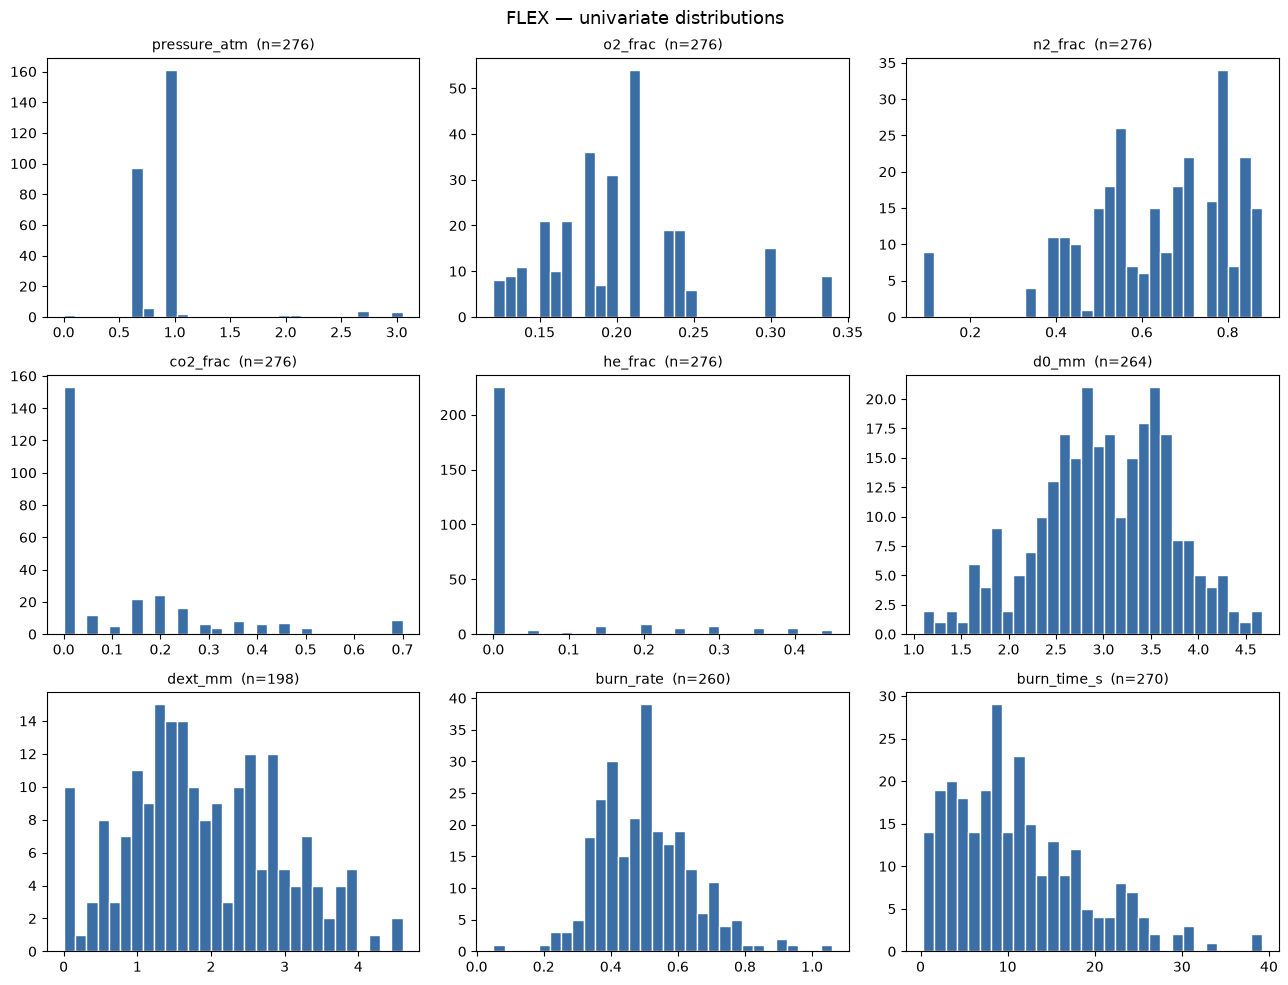

In [19]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, c in zip(axes.flat, num):
    ax.hist(df[c].dropna(), bins=30, color='#3b6ea5', edgecolor='white')
    ax.set_title(f'{c}  (n={df[c].notna().sum()})', fontsize=10)
fig.suptitle('FLEX — univariate distributions', fontsize=13)
fig.tight_layout(); fig.savefig('figures/flex_univariate.png', dpi=110); plt.show()

In [20]:
print('Distinct values of design variables (chosen by the experimenters):')
for c in ['pressure_atm','o2_frac','co2_frac','he_frac']:
    v = df[c].round(2).value_counts().sort_index()
    print(c, v.to_dict())

Distinct values of design variables (chosen by the experimenters):
pressure_atm {0.0: 1, 0.69: 4, 0.7: 60, 0.71: 37, 0.72: 2, 0.99: 8, 1.0: 73, 1.01: 78, 1.02: 4, 2.03: 1, 2.04: 1, 2.7: 1, 2.72: 1, 2.73: 2, 3.05: 3}
o2_frac {0.12: 8, 0.13: 9, 0.14: 11, 0.15: 21, 0.16: 10, 0.17: 21, 0.18: 36, 0.19: 7, 0.2: 31, 0.21: 54, 0.23: 19, 0.24: 19, 0.25: 6, 0.3: 15, 0.34: 9}
co2_frac {0.0: 153, 0.05: 12, 0.1: 5, 0.15: 22, 0.2: 24, 0.25: 16, 0.3: 6, 0.32: 4, 0.35: 6, 0.36: 2, 0.4: 6, 0.45: 7, 0.5: 4, 0.7: 9}
he_frac {0.0: 225, 0.05: 4, 0.1: 2, 0.15: 7, 0.2: 9, 0.25: 6, 0.3: 7, 0.35: 6, 0.4: 6, 0.45: 4}


### 3.5 Support and report notes vs. outcome

In [21]:
print(pd.crosstab([df['fuel'], df['support']], df['test_end'], margins=True))
flags = ['left_fov','extrapolated','not_reliable','not_measurable','fiber_dislodged','oscillation','cool_flame','soot_mentioned']
print()
print(df.groupby('test_end')[flags].sum())

test_end          Completion  Disruption  Extinction  All
fuel     support                                         
Heptane  fiber             7           8          14   29
         free             13          31          46   90
Methanol fiber             3          15          17   35
         free              5           8         109  122
All                       28          62         186  276

            left_fov  extrapolated  not_reliable  not_measurable  fiber_dislodged  oscillation  cool_flame  soot_mentioned
test_end                                                                                                                  
Completion        16             4             0               0                2            8           1               3
Disruption        27             3             2               1                8           19           0              13
Extinction        87            21             2               0                1           37       

In [22]:
print('cool flame mentions by fuel:', df.groupby('fuel')['cool_flame'].sum().to_dict())
print('extinction diameter missing, by left_fov:')
print(pd.crosstab(df['left_fov'], df['dext_mm'].isna(), rownames=['left camera view'], colnames=['dext missing']))

cool flame mentions by fuel: {'Heptane': 54, 'Methanol': 0}
extinction diameter missing, by left_fov:
dext missing      False  True 
left camera view              
False               118     28
True                 80     50


### 3.6 Findings (univariate, 276 tests)

- **Experimental conditions are complete** (pressure, O2, N2, CO2, He, fuel, support: 276/276). Gaps are only in measured results: extinction diameter 78 empty (only 27 truly missing, see §5), burning rate 16, initial diameter 12, burn time 6.
- **Pressure levels chosen by the experimenters:** ~0.70 atm (103 tests), ~1.0 atm (163), 2–3 atm (9), and one 0 (test 114 → §4, DD-010).
- **Outcome:** Extinction 186 / Disruption 62 / Completion 28. Methanol ends mostly in Extinction (126/157); heptane is more mixed.
- **Diluents:** CO2 123, N2 only 102, He 51; CO2 and He are never mixed.
- **Support:** 212 free-floating, 64 fiber-supported. It is associated with the outcome (methanol: free 109/122 Extinction vs. fiber 17/35) → confounder, must enter the model.
- **Cool flames** are mentioned in 54 tests, all heptane.
- Gas fractions sum to 0.98–1.01 (rounding, DD-015). Burning rate is in mm²/s (report).
- Odd values (pressure 0, duplicate id, extreme rates…) are detailed and decided in §4.

## 4. Odd values: detail and decisions

**Method (decided by Lautaro, applied case by case, not an automatic rule):** 1) physically possible → outlier → kept; 2) impossible → look for the explanation (0 = not recorded, wrong unit, lost decimal); 3) if the true value can be recovered with strong evidence (series, document) → corrected with a flag, otherwise NaN with a flag; 4) the row is always kept unless it is not a test. Decisions are logged as DD-010 to DD-015 in the team's `DECISIONES_DATOS.md`.

In [23]:
show = ['test_no','flex_id','date_raw','fuel','pressure_mmhg','o2_frac','co2_frac','he_frac','d0_mm','dext_mm','burn_rate','burn_time_s','test_end']
# Test 114 next to the tests of its own series (same conditions)
df.loc[df['flex_id'].str.startswith('C11'), show]

,test_no,flex_id,date_raw,fuel,pressure_mmhg,o2_frac,co2_frac,he_frac,d0_mm,dext_mm,burn_rate,burn_time_s,test_end
112,113,C11M101,9/1/2010,Methanol,534.6,0.2,0.35,0.0,4.20,2.85,0.49,18.2,Extinction
113,114,C11M201,9/6/2010,Methanol,0.0,0.2,0.35,0.0,3.23,1.68,0.42,18.9,Extinction
114,115,C11M301,9/1/2010,Methanol,535.8,0.2,0.35,0.0,3.97,2.61,0.41,22.9,Extinction
115,116,C11M401,9/1/2010,Methanol,536.3,0.2,0.35,0.0,3.16,1.57,0.46,16.9,Extinction
116,117,C11H101,9/6/2010,Heptane,531.1,0.2,0.35,0.0,3.84,3.77,0.25,2.4,Extinction
117,118,C11H201,9/6/2010,Heptane,532.8,0.2,0.35,0.0,3.03,2.93,0.38,2.5,Extinction


**DD-010 (decided) — Test 114, pressure = 0.** Impossible as a measurement; it means 'not recorded'. Pressure is a set condition of the experiment, so it is recovered from the same-day tests of its series (C11H101 531.1, C11H201 532.8 mmHg → 531.95 mmHg, ~0.70 atm), flag `imputed_by_series`, raw 0 kept. Same-condition tests on 9/1 are at 534.6–536.3 mmHg: difference < 1%. No outcome information is used → no leakage.

In [24]:
# DD-010 (decided): pressure 0 = not recorded -> recovered from same-day tests of the same series (C11H101, C11H201)
m = df['test_no'].eq('114')
same_day = df['flex_id'].isin(['C11H101','C11H201'])
p_series = df.loc[same_day, 'pressure_mmhg'].mean()
df.loc[m, 'pressure_mmhg'] = p_series
df.loc[m, 'pressure_mmhg_flag'] = 'imputed_by_series'
df['pressure_kpa'] = df['pressure_mmhg'] * 0.133322
df['pressure_atm'] = df['pressure_mmhg'] / 760
df.loc[m, ['test_no','pressure_mmhg_raw','pressure_mmhg','pressure_atm','pressure_mmhg_flag']]

,test_no,pressure_mmhg_raw,pressure_mmhg,pressure_atm,pressure_mmhg_flag
113,114,0,531.95,0.699934,imputed_by_series


In [25]:
# Test 129: extinction diameter > initial diameter
df.loc[df['dext_mm'] > df['d0_mm'], show]

,test_no,flex_id,date_raw,fuel,pressure_mmhg,o2_frac,co2_frac,he_frac,d0_mm,dext_mm,burn_rate,burn_time_s,test_end
128,129,C13H102,9/17/2010,Heptane,536.2,0.17,0.45,0.0,3.33,3.34,0.33,0.55,Extinction


**DD-011 (decided: no change) — Test 129 is NOT an error.** The difference is 0.01 mm, within the measurement resolution (2 decimals); the flame went out after 0.55 s, before the droplet was consumed, and a heating droplet swells slightly. Kept as is.

In [26]:
# Extinction diameter = 0, and missing extinction diameter by outcome
print(df.loc[df['dext_mm'] == 0, show].to_string(index=False))
print()
print(pd.crosstab(df['test_end'], df['dext_mm'].isna().map({True:'dext missing', False:'dext present'})))
print()
print('Completion tests with dext > 0:')
print(df.loc[(df['test_end']=='Completion') & (df['dext_mm']>0), show].to_string(index=False))

test_no flex_id  date_raw    fuel  pressure_mmhg  o2_frac  co2_frac  he_frac  d0_mm  dext_mm  burn_rate  burn_time_s   test_end
     39 224F001  1/7/2010 Heptane          534.9     0.34      0.00      0.0   2.91      0.0       0.80          9.9 Disruption
     43 223F002  1/8/2010 Heptane          534.9     0.30      0.00      0.0   2.97      0.0       0.78         11.4 Disruption
     51 209F005 1/19/2010 Heptane          771.4     0.21      0.00      0.0   2.41      0.0       0.65          8.2 Completion
     52 210F002 1/11/2010 Heptane          771.1     0.30      0.00      0.0   3.53      0.0       0.70         18.3 Disruption
     63 301F002 3/11/2010 Heptane          767.6     0.18      0.00      0.0   2.15      0.0       0.51          9.6 Completion
     69 193R002 3/23/2010 Heptane          767.1     0.14      0.00      0.0   1.10      0.0       0.94          1.3 Completion
     93 149F001 6/15/2010 Heptane          537.3     0.25      0.15      0.0   2.48      0.0       0.71 

**DD-012 (open) — dext = 0 (8 tests) kept; open question.** Not impossible (4 Completion, 4 Disruption). But the meaning of `0` vs. empty, and of the `Completion` / `Disruption` categories, must be confirmed in the FLEX documentation: several `Completion` tests have dext > 0.

In [27]:
df.loc[df['flex_id'].duplicated(keep=False), show]

,test_no,flex_id,date_raw,fuel,pressure_mmhg,o2_frac,co2_frac,he_frac,d0_mm,dext_mm,burn_rate,burn_time_s,test_end
69,70,193F001,3/23/2010,Heptane,761.0,0.15,0.0,0.0,4.67,4.60,0.41,1.6,Extinction
72,73,193F001,3/23/2010,Heptane,761.0,0.15,0.0,0.0,4.64,4.58,0.56,1.5,Extinction


**DD-013 (decided) — Tests 70 and 73: same test loaded twice.** Both rows kept in the clean layer with flag `duplicate_id`. For modeling (L3) they become **one test**: averaged where they agree (d0 4.655 mm, dext 4.59 mm, burn time 1.55 s) and **burn rate left empty** (0.41 vs 0.56 contradict each other), flag `conflicting_values`.

In [28]:
df['duplicate_id'] = df['flex_id'].duplicated(keep=False)
print(df.sort_values('burn_rate').dropna(subset=['burn_rate']).iloc[[0,1,-2,-1]][show].to_string(index=False))

test_no flex_id  date_raw     fuel  pressure_mmhg  o2_frac  co2_frac  he_frac  d0_mm  dext_mm  burn_rate  burn_time_s   test_end
    130 C13H201 9/17/2010  Heptane          537.2     0.17      0.45     0.00   2.91     2.89       0.05          0.6 Extinction
    140 C14M101 11/4/2010 Methanol          533.5     0.15      0.50     0.00   3.98     3.95       0.20          1.3 Extinction
     69 193R002 3/23/2010  Heptane          767.1     0.14      0.00     0.00   1.10     0.00       0.94          1.3 Completion
    270 H15H201  11/30/11  Heptane          532.5     0.17      0.00     0.45   1.61     0.91       1.06          1.4 Completion


**DD-014 (decided: no change) — Extreme burning rates are kept (outliers, not impossible).** Test 130 (0.05) went out after 0.6 s with the droplet almost intact: a rate measured over <~1 s is unreliable (note for modeling). Test 270 (1.06) has 45% He, which raises thermal diffusivity: a high rate is physically expected.

**DD-015 (decided: no change) — Composition sums 0.98–1.01:** rounding, not an error. Models will use O2, CO2, He (N2 is the remainder).

## 5. Missing values

Cycle (decided by Lautaro): analysis → conclusions → discussion → decision → action. **This section only analyses; nothing is imputed or removed here.**

### 3.1 How much is missing, per column

In [29]:
cols = ['pressure_mmhg','o2_frac','n2_frac','co2_frac','he_frac','d0_mm','dext_mm','burn_rate','burn_time_s','support']
miss = pd.DataFrame({'missing': df[cols].isna().sum(), 'pct': (df[cols].isna().mean()*100).round(1)})
miss.sort_values('pct', ascending=False)

,missing,pct
dext_mm,78,28.3
burn_rate,16,5.8
d0_mm,12,4.3
burn_time_s,6,2.2
o2_frac,0,0.0
pressure_mmhg,0,0.0
he_frac,0,0.0
co2_frac,0,0.0
n2_frac,0,0.0
support,0,0.0


### 5.1 Extinction diameter: 'missing' or 'does not exist'?
By NASA's definition, a test that ended in `Completion` or `Disruption` has **no extinction diameter** (the flame never went out with fuel left). That is not missing data; it is the correct answer. Only `Extinction` tests without a diameter are truly missing.

In [30]:
# Outcome vs. extinction-diameter availability, read with the report's definitions
state = np.select([df['dext_mm'].isna(), df['dext_mm'].eq(0)], ['no finite extinction / not measured', 'zero (no droplet left)'], 'finite extinction diameter')
pd.crosstab(df['test_end'], state)

col_0,finite extinction diameter,no finite extinction / not measured,zero (no droplet left)
test_end,,,
Completion,11,13,4
Disruption,20,38,4
Extinction,159,27,0


In [31]:
is_na = df['dext_mm'].isna()
tab = pd.crosstab(df['test_end'], is_na.map({True:'no value', False:'has value'}), margins=True)
print(tab)
true_missing = df[(df['test_end']=='Extinction') & is_na]
print(); print('Truly missing (Extinction without diameter):', len(true_missing), 'of', (df['test_end']=='Extinction').sum(), f"({len(true_missing)/(df['test_end']=='Extinction').sum()*100:.1f}%)")

dext_mm     has value  no value  All
test_end                            
Completion         15        13   28
Disruption         24        38   62
Extinction        159        27  186
All               198        78  276

Truly missing (Extinction without diameter): 27 of 186 (14.5%)


In [32]:
# Why are those Extinction diameters missing? Compare with the report's notes and with conditions
ext = df[df['test_end']=='Extinction'].copy()
ext['dext_missing'] = ext['dext_mm'].isna()
print(pd.crosstab(ext['left_fov'], ext['dext_missing'], rownames=['left camera view'], colnames=['dext missing']))
print()
for c in ['fuel','support','diluent']:
    print(pd.crosstab(ext[c], ext['dext_missing'], normalize='index').round(2).rename(columns={True:'% missing', False:'% present'})); print()
print(ext.groupby('dext_missing')[['o2_frac','pressure_atm','d0_mm','burn_time_s']].median().round(2))

dext missing      False  True 
left camera view              
False                91      8
True                 68     19

dext_missing  % present  % missing
fuel                              
Heptane            0.93       0.07
Methanol           0.82       0.18

dext_missing  % present  % missing
support                           
fiber              0.87       0.13
free               0.85       0.15

dext_missing  % present  % missing
diluent                           
CO2                0.89       0.11
He                 0.88       0.12
N2 only            0.79       0.21



              o2_frac  pressure_atm  d0_mm  burn_time_s
dext_missing                                           
False            0.18           1.0   3.02          8.2
True             0.18           1.0   3.42         12.0


### 5.2 Other columns with gaps (initial diameter, burning rate, burn time)

In [33]:
other = df[df[['d0_mm','burn_rate','burn_time_s']].isna().any(axis=1)]
print('tests with a gap in d0 / burning rate / burn time:', len(other))
print(other[['flex_no','flex_id','fuel','test_end','d0_mm','burn_rate','burn_time_s','left_fov','not_reliable','not_measurable']].to_string(index=False))

tests with a gap in d0 / burning rate / burn time: 17
 flex_no flex_id     fuel   test_end  d0_mm  burn_rate  burn_time_s  left_fov  not_reliable  not_measurable
       9 30CAL07  Heptane Disruption    NaN        NaN          NaN      True         False           False
      12 264F003  Heptane Disruption   2.74        NaN          NaN      True         False           False
      14 256F007 Methanol Extinction   3.70        NaN        11.30      True         False           False
      15 256F008 Methanol Extinction   4.42        NaN        23.10      True         False           False
      17 240R003 Methanol Disruption   2.67        NaN         2.40     False         False           False
      24 196F003  Heptane Disruption    NaN        NaN          NaN     False         False           False
      53 209F002  Heptane Disruption    NaN        NaN        18.50      True         False           False
      80 207F001  Heptane Extinction    NaN        NaN         1.00     False     

In [34]:
# Rows with many gaps at once (Lautaro: a row with most columns empty cannot be imputed)
meas = ['d0_mm','dext_mm','burn_rate','burn_time_s']
gaps = df[meas].isna().sum(axis=1)
print('measured-value gaps per test (out of 4):', gaps.value_counts().sort_index().to_dict())
print(df.loc[gaps>=3, ['flex_no','flex_id','fuel','test_end']+meas].to_string(index=False))

measured-value gaps per test (out of 4): {0: 197, 1: 63, 2: 3, 3: 9, 4: 4}
 flex_no flex_id     fuel   test_end  d0_mm  dext_mm  burn_rate  burn_time_s
       9 30CAL07  Heptane Disruption    NaN      NaN        NaN          NaN
      12 264F003  Heptane Disruption   2.74      NaN        NaN          NaN
      24 196F003  Heptane Disruption    NaN      NaN        NaN          NaN
      53 209F002  Heptane Disruption    NaN      NaN        NaN        18.50
      80 207F001  Heptane Extinction    NaN      NaN        NaN         1.00
      81 207F002  Heptane Extinction    NaN      NaN        NaN         1.50
      83 304F002 Methanol Extinction    NaN      NaN        NaN         5.45
      96 C08H301  Heptane Disruption    NaN      NaN        NaN         5.20
     138 C21H304  Heptane Disruption    NaN      NaN        NaN          NaN
     212 N02H201  Heptane Extinction    NaN      NaN        NaN          NaN
     227 H01M104 Methanol Extinction    NaN      NaN        NaN         6.00
 

### 5.3 Conclusions and decisions (decided by Lautaro, DD-019 to DD-021)

**Conclusions**
1. Experimental conditions are complete (pressure, gases, fuel, support: 0 gaps).
2. Extinction diameter: of the empty values, most are tests that ended in `Completion`/`Disruption`, where the diameter **does not exist** by definition. Only the `Extinction` tests without a diameter are truly missing (see 5.1).
3. Those true gaps are not random: more frequent when the droplet left the camera view, for methanol, in N2-only atmospheres, and in larger, longer-burning droplets — a longer burn gives the droplet more time to drift out of view.
4. A small group of tests has almost nothing measured (3–4 of 4 measured values empty), but their conditions and outcome are valid.
5. What must be imputed depends on what the model uses: a model of *how the test ends* from the *conditions* only lacks the initial droplet size in a few tests.

**Decisions**
- **DD-019 — Extinction diameter is not imputed.** It is a result, not an input; in most empty cells it does not exist; and the true gaps are not random, so imputing would invent exactly the hardest-to-measure cases. Models of this diameter use only `Extinction` tests that have it.
- **DD-020 — Missing initial size: those tests are left out only of models that use size** (they stay in the data). They are the same nearly-empty tests; imputing would be guessing, and they are few.
- **DD-021 — The nearly-empty tests are used in the 'how does the test end' model**, which only needs conditions and outcome.

## 6. Outcome vs. experimental conditions

Question: how does the way a test ends change with oxygen, pressure, CO2, helium, fuel, support and droplet size?

Because `Disruption` is partly an artifact (fuel contaminant, per NASA), two views are shown:
- **A — all tests:** share of `Extinction` among all tests.
- **B — without Disruption:** `Extinction` vs. `Completion` only (the droplet either went out with fuel left, or burned completely).

Only analysis here; nothing is decided.

In [35]:
df['extinct'] = df['test_end'].eq('Extinction')
clean = df[df['test_end'] != 'Disruption']
def rates(col, bins=None):
    a = df[col] if bins is None else pd.cut(df[col], bins)
    b = clean[col] if bins is None else pd.cut(clean[col], bins)
    out = pd.DataFrame({'n_all': df.groupby(a, observed=True).size(),
                        'A_ext_rate_all': df.groupby(a, observed=True)['extinct'].mean().round(2),
                        'n_noDisr': clean.groupby(b, observed=True).size(),
                        'B_ext_rate_noDisr': clean.groupby(b, observed=True)['extinct'].mean().round(2)})
    return out
for c in ['fuel', 'support', 'diluent']:
    print(rates(c)); print()

          n_all  A_ext_rate_all  n_noDisr  B_ext_rate_noDisr
fuel                                                        
Heptane     119             0.5        80               0.75
Methanol    157             0.8       134               0.94

         n_all  A_ext_rate_all  n_noDisr  B_ext_rate_noDisr
support                                                    
fiber       64            0.48        41               0.76
free       212            0.73       173               0.90

         n_all  A_ext_rate_all  n_noDisr  B_ext_rate_noDisr
diluent                                                    
CO2        123            0.72        96               0.92
He          51            0.78        46               0.87
N2 only    102            0.57        72               0.81



In [36]:
print('Oxygen'); print(rates('o2_frac', [0.11, 0.14, 0.17, 0.20, 0.22, 0.26, 0.35]))
print(); print('Pressure (atm)'); print(rates('pressure_atm', [0.5, 0.8, 1.2, 3.1]))
print(); print('CO2 fraction'); print(rates('co2_frac', [-0.01, 0.0, 0.15, 0.30, 0.71]))
print(); print('He fraction'); print(rates('he_frac', [-0.01, 0.0, 0.2, 0.46]))
print(); print('Initial droplet size (mm)'); print(rates('d0_mm', [1.0, 2.5, 3.0, 3.5, 4.7]))

Oxygen
              n_all  A_ext_rate_all  n_noDisr  B_ext_rate_noDisr
o2_frac                                                         
(0.11, 0.14]     28            0.96        28               0.96
(0.14, 0.17]     52            0.88        51               0.90
(0.17, 0.2]      74            0.80        66               0.89
(0.2, 0.22]      54            0.63        40               0.85
(0.22, 0.26]     44            0.41        23               0.78
(0.26, 0.35]     24            0.08         6               0.33

Pressure (atm)
              n_all  A_ext_rate_all  n_noDisr  B_ext_rate_noDisr
pressure_atm                                                    
(0.5, 0.8]      104            0.62        73               0.88
(0.8, 1.2]      163            0.71       134               0.86
(1.2, 3.1]        9            0.78         7               1.00

CO2 fraction


              n_all  A_ext_rate_all  n_noDisr  B_ext_rate_noDisr
co2_frac                                                        
(-0.01, 0.0]    153            0.64       118               0.83
(0.0, 0.15]      39            0.64        27               0.93
(0.15, 0.3]      46            0.59        33               0.82
(0.3, 0.71]      38            0.95        36               1.00

He fraction
              n_all  A_ext_rate_all  n_noDisr  B_ext_rate_noDisr
he_frac                                                         
(-0.01, 0.0]    225            0.65       168               0.87
(0.0, 0.2]       22            0.64        18               0.78
(0.2, 0.46]      29            0.90        28               0.93

Initial droplet size (mm)
            n_all  A_ext_rate_all  n_noDisr  B_ext_rate_noDisr
d0_mm                                                         
(1.0, 2.5]     59            0.58        46               0.74
(2.5, 3.0]     72            0.72        58             

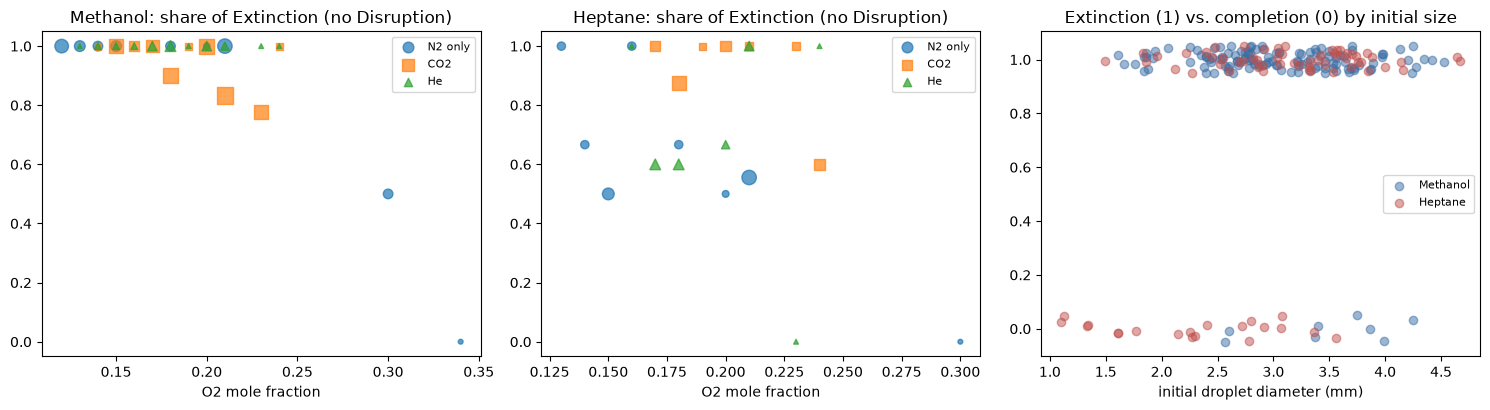

In [37]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, fuel in zip(axes[:2], ['Methanol', 'Heptane']):
    sub = clean[clean['fuel'] == fuel]
    for dil, mk in [('N2 only','o'), ('CO2','s'), ('He','^')]:
        s = sub[sub['diluent'] == dil].groupby('o2_frac')['extinct'].agg(['mean','size'])
        ax.scatter(s.index, s['mean'], s=s['size']*12, marker=mk, alpha=0.7, label=dil)
    ax.set_title(f'{fuel}: share of Extinction (no Disruption)'); ax.set_xlabel('O2 mole fraction'); ax.set_ylim(-0.05, 1.05); ax.legend(fontsize=8)
ax = axes[2]
for fuel, col in [('Methanol','#3b6ea5'), ('Heptane','#c0504d')]:
    s = clean[clean['fuel']==fuel]
    ax.scatter(s['d0_mm'], s['extinct'] + np.random.uniform(-0.05, 0.05, len(s)), alpha=0.5, label=fuel, color=col)
ax.set_title('Extinction (1) vs. completion (0) by initial size'); ax.set_xlabel('initial droplet diameter (mm)'); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig('figures/flex_outcome_vs_conditions.png', dpi=110); plt.show()

In [38]:
# Same oxygen, low vs. ~1 atm pressure (methanol and heptane, no Disruption)
clean2 = clean.assign(p_level=np.where(clean['pressure_atm'] < 0.8, '0.7 atm', np.where(clean['pressure_atm'] < 1.2, '1 atm', '2-3 atm')))
print(pd.crosstab([clean2['fuel'], clean2['p_level']], clean2['extinct'], margins=True))

extinct           False  True  All
fuel     p_level                  
Heptane  0.7 atm      3    22   25
         1 atm       17    37   54
         2-3 atm      0     1    1
Methanol 0.7 atm      6    42   48
         1 atm        2    78   80
         2-3 atm      0     6    6
All                  28   186  214


### 6.1 Conclusions (for discussion — nothing decided)

One-variable views only: in this experiment variables were changed together by design, so these are hints, not effects. A model is needed to separate them.

1. **Oxygen is the clearest signal:** with little O2 the flame goes out with fuel left almost always (12–14% O2: 96%); with a lot of O2 it almost never does (26–34% O2: 8% of all tests). More oxygen → the droplet tends to burn completely.
2. **Suppressants work at high doses:** with >30% CO2 the flame goes out early 95–100% of the time; with >20% He, ~90%. At lower doses the effect is not clear in these simple views.
3. **Methanol goes out early more than heptane** (94% vs 75% without Disruption).
4. **Fiber-supported droplets go out early less than free ones** (76% vs 90%) — the support matters (confirms it must enter the model).
5. **Small droplets (≤2.5 mm) go out early less** (74% vs ~90%): they tend to burn completely before the flame dies.
6. **Pressure:** no clear effect on its own here.
7. **Key warning — high oxygen has little clean evidence:** at 26–34% O2 most tests ended in `Disruption` (partly an artifact). Without them, only 6 tests remain. The 'exploration atmosphere' zone is exactly where FLEX evidence is thinnest.

**Decision needed before modeling — how to treat `Disruption` in the outcome:** (a) model Extinction vs. Completion and leave Disruption out of training (loses 62 tests, mostly high O2) and report it separately; (b) count Disruption as 'did not extinguish' (mixes an artifact into the outcome); (c) three outcomes.

### 6.2 Decision on `Disruption` (DD-022) and the needle contamination

**Decided by Lautaro (2026-11-14), after a debate between agents (`JUICIO_DISRUPTION_FLEX.md` in the team docs):** main model = 'if the droplet does not break, does the flame go out or does it burn completely?' (214 tests); a separate small model for the risk of disruption (276 tests); a sensitivity analysis (all Disruption counted as Extinction, then as Completion); the high-oxygen zone flagged as 'little clean evidence'.

**What the report says about the contamination (NASA/TP-2015-216046 §5.2):** the fuel needles had a conformal coating that dissolved and flaked into the fuel. New uncoated needles were flown, and *'all tests subsequent to these (to be reported in the future) will not have contamination'*. → **Every test in this dataset used the contaminated needles.** There is no 'clean' group to compare with, so test date or series cannot be used as a contamination batch. NASA also states that burning rates and flame histories were minimally affected; disruptive extinction of methanol is probably due to the contaminant.

In [39]:
# Does the disruption rate change over time? (coating could wear off or accumulate)
df['half_year'] = df['test_date'].dt.year.astype(str) + '-H' + np.where(df['test_date'].dt.month <= 6, '1', '2')
print(pd.crosstab([df['half_year']], [df['fuel'], df['test_end']=='Disruption']).rename(columns={True:'disr', False:'other'}))

fuel      Heptane      Methanol     
test_end    other disr    other disr
half_year                           
2009-H1         0    4       11    1
2009-H2         3    6        7    4
2010-H1        23    8       26   15
2010-H2        14    8       35    0
2011-H1         5    5        6    1
2011-H2        35    8       49    2


**Findings (6.2):**
- **Methanol disruptions cluster in an early period:** 19 of its 23 disruptions happened between late 2009 and mid 2010; afterwards almost none (0 in 2010-H2, 3 in 2011). But the high-oxygen campaign was also run early (tests at 30–34% O2 in Aug–Nov 2009), so **period and oxygen are mixed up** in the data: we cannot tell whether it was the state of the needles or the oxygen.
- **Heptane disruptions appear in every period.**
- Consequence for the plan: the 'test series/date as contamination batch' idea from the verdict is **not viable** (no clean tests in this dataset). The rest of the verdict stands; the high-oxygen zone is even more clearly 'little clean evidence'.

## 7. Coverage of the experimental design: where there is data and where there is not

The experimenters chose the conditions, so the data only covers some combinations. This section maps them; it later defines when the product must say 'no evidence here'. Counts are shown for all tests and for **clean** tests (without `Disruption`, i.e. usable by the main model, DD-022).

In [40]:
df['p_level'] = np.select([df['pressure_atm'] < 0.8, df['pressure_atm'] < 1.2], ['0.7 atm', '1 atm'], '2-3 atm')
df['clean'] = df['test_end'] != 'Disruption'
df['o2_pct'] = (df['o2_frac'] * 100).round().astype(int)
print('ALL tests (rows: O2 %, columns: pressure level / diluent)')
print(pd.crosstab(df['o2_pct'], [df['p_level'], df['diluent']]))
print()
print('CLEAN tests (no Disruption)')
print(pd.crosstab(df.loc[df['clean'],'o2_pct'], [df.loc[df['clean'],'p_level'], df.loc[df['clean'],'diluent']]))

ALL tests (rows: O2 %, columns: pressure level / diluent)
p_level 0.7 atm            1 atm            2-3 atm
diluent     CO2 He N2 only   CO2 He N2 only     CO2
o2_pct                                             
12            0  0       0     0  0       8       0
13            0  0       0     0  1       8       0
14            0  0       0     2  2       7       0
15            4  0       0     4  2      11       0
16            0  0       0     4  3       3       0
17            7  4       0     4  6       0       0
18            6  5       0    13  5       7       0
19            0  0       0     5  2       0       0
20            6  4       5    12  4       0       0
21            6  5       0     3  2      29       9
23           16  3       0     0  0       0       0
24            7  3       0     9  0       0       0
25            6  0       0     0  0       0       0
30            0  0       8     0  0       7       0
34            0  0       9     0  0       0       0

CLEAN

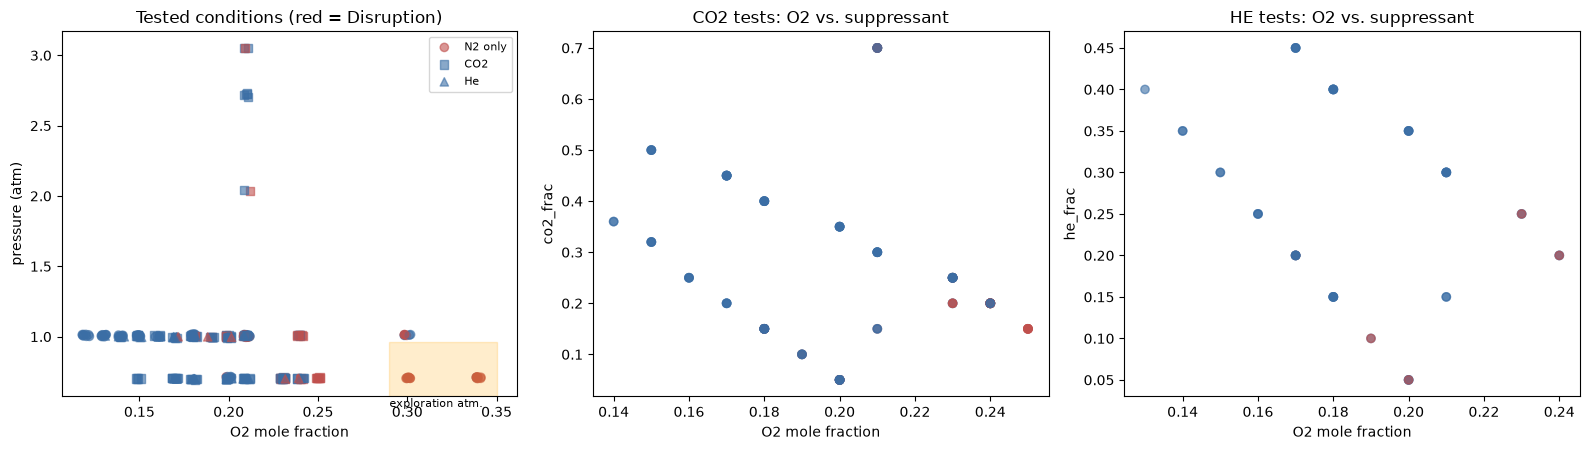

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
mk = {'N2 only':'o', 'CO2':'s', 'He':'^'}
for dil, m in mk.items():
    s = df[df['diluent']==dil]
    axes[0].scatter(s['o2_frac'] + np.random.uniform(-0.002, 0.002, len(s)), s['pressure_atm'], marker=m, alpha=0.6, label=dil, c=np.where(s['clean'], '#3b6ea5', '#c0504d'))
axes[0].set_xlabel('O2 mole fraction'); axes[0].set_ylabel('pressure (atm)'); axes[0].set_title('Tested conditions (red = Disruption)')
axes[0].axvspan(0.29, 0.35, ymin=0.0, ymax=0.15, color='orange', alpha=0.2)
axes[0].text(0.29, 0.5, 'exploration atm.', fontsize=8)
axes[0].legend(fontsize=8)
for ax, sup in zip(axes[1:], ['co2_frac', 'he_frac']):
    s = df[df[sup] > 0]
    ax.scatter(s['o2_frac'], s[sup], c=np.where(s['clean'], '#3b6ea5', '#c0504d'), alpha=0.6)
    ax.set_xlabel('O2 mole fraction'); ax.set_ylabel(sup); ax.set_title(f'{sup.split("_")[0].upper()} tests: O2 vs. suppressant')
fig.tight_layout(); fig.savefig('figures/flex_coverage.png', dpi=110); plt.show()

### 7.1 The exploration atmosphere (~0.70 atm, 30–34% O2) in detail

In [42]:
expl = df[(df['p_level']=='0.7 atm') & (df['o2_frac'] >= 0.29)]
print('tests at ~0.70 atm with >=30% O2:', len(expl))
print(expl[['flex_no','flex_id','fuel','o2_frac','co2_frac','he_frac','support','d0_mm','test_end','cool_flame']].sort_values(['fuel','o2_frac']).to_string(index=False))
print()
print('same O2 range at 1 atm:', len(df[(df['p_level']=='1 atm') & (df['o2_frac'] >= 0.29)]))
print(df[(df['p_level']=='1 atm') & (df['o2_frac'] >= 0.29)][['flex_no','fuel','o2_frac','support','test_end']].to_string(index=False))

tests at ~0.70 atm with >=30% O2: 17
 flex_no flex_id     fuel  o2_frac  co2_frac  he_frac support  d0_mm   test_end  cool_flame
      27 195F001  Heptane     0.30       0.0      0.0    free   3.87 Disruption       False
      28 195F002  Heptane     0.30       0.0      0.0    free   3.36 Disruption       False
      42 223F001  Heptane     0.30       0.0      0.0   fiber   2.92 Disruption       False
      43 223F002  Heptane     0.30       0.0      0.0   fiber   2.97 Disruption       False
      19 196F001  Heptane     0.34       0.0      0.0    free   3.39 Disruption       False
      23 196F002  Heptane     0.34       0.0      0.0    free   3.01 Disruption       False
      24 196F003  Heptane     0.34       0.0      0.0    free    NaN Disruption       False
      39 224F001  Heptane     0.34       0.0      0.0   fiber   2.91 Disruption       False
      25 191R001 Methanol     0.30       0.0      0.0    free   2.60 Completion       False
      26 191F001 Methanol     0.30       0.

### 7.2 Design gaps

In [43]:
print('O2 range tested with each diluent and pressure level (clean tests):')
g = df[df['clean']].groupby(['fuel','p_level','diluent'])['o2_frac'].agg(['size','min','max']).round(2)
print(g)
print()
print('Suppressant doses tested (clean tests):')
for sup in ['co2_frac','he_frac']:
    print(sup, df[df['clean'] & (df[sup]>0)].groupby('fuel')[sup].agg(['size','min','max']).round(2).to_dict('index'))
print()
print('Supported (fiber) tests by pressure level:', df[df['support']=='fiber'].groupby('p_level').size().to_dict())

O2 range tested with each diluent and pressure level (clean tests):
                          size   min   max
fuel     p_level diluent                  
Heptane  0.7 atm CO2        13  0.17  0.24
                 He         10  0.17  0.24
                 N2 only     2  0.20  0.20
         1 atm   CO2        16  0.17  0.24
                 He         10  0.16  0.21
                 N2 only    28  0.13  0.30
         2-3 atm CO2         1  0.21  0.21
Methanol 0.7 atm CO2        32  0.15  0.24
                 He         12  0.17  0.24
                 N2 only     4  0.20  0.34
         1 atm   CO2        28  0.14  0.21
                 He         14  0.13  0.20
                 N2 only    38  0.12  0.30
         2-3 atm CO2         6  0.21  0.21

Suppressant doses tested (clean tests):
co2_frac {'Heptane': {'size': 30, 'min': 0.05, 'max': 0.7}, 'Methanol': {'size': 66, 'min': 0.05, 'max': 0.7}}
he_frac {'Heptane': {'size': 20, 'min': 0.05, 'max': 0.45}, 'Methanol': {'size': 26, 'min': 

### 7.3 Conclusions (for discussion — nothing decided)

1. **The exploration atmosphere (~0.70 atm, 30–34% O2) has 17 tests but only 2 clean ones** — both methanol, both `Completion` (the droplet burned completely). **Heptane: 0 clean tests** (8 of 8 Disruption).
2. **No suppressant was ever tested at high oxygen.** CO2 and He tests only go up to 24–25% O2. The question 'how much CO2 or helium puts out a fire in the exploration atmosphere?' has **no data in FLEX**.
3. **The main model's clean evidence lives between 12% and 24% O2**, at ~0.70 and ~1 atm. 2–3 atm was only tested at 21% O2 with CO2 (7 clean tests).
4. At 1 atm and 30% O2 there are 7 tests (4 clean): a little more evidence, but not at the exploration pressure.
5. Fiber-supported tests exist at both 0.70 atm (37) and 1 atm (27).

**Proposal for the product (to discuss):** the 'inside the data' check (`in_domain`) should not only look at each variable's range, but at the **combination**: e.g. 'CO2 at 30% O2' is outside the data even though both values exist separately. A simple rule: a query is inside the data if there are clean tests with the same fuel, same diluent type and same pressure level within ±2 points of O2 and ±5 points of suppressant.

**Decision (Lautaro, 2026-11-14):** the 'inside the data' check works on the **combination** (same fuel, same suppressant, same pressure level, similar O2 and suppressant dose among clean tests). When a query falls outside, the system **answers that it does not know and explains why** (which combination was never tested and which are the closest real tests). It does not return a number.

## 8. Dependencies between tests (for honest model evaluation)

If two tests are almost the same (same chamber fill, same day, same condition) and one lands in training while the other lands in testing, the evaluation looks better than reality (leakage). This section looks for such groups. NASA's report (§2.3) says the chamber atmosphere was **frequently reused** between tests.

In [44]:
# Structure of the CIR identifier, e.g. C11M201 / 192F001 / H04H302 / N03H201 / 20CAL08
import re
id_re = r'^([A-Z]?\d{2,3})([A-Z])(\d)(\d{2,3})$'
parts = df['flex_id'].str.extract(id_re)
df['id_condition'] = parts[0]; df['id_letter'] = parts[1]; df['id_digit'] = parts[2]
print('ids not matching the pattern:', df.loc[parts[0].isna(), 'flex_id'].tolist())
print(pd.crosstab(df['id_letter'], df['fuel']))
print(pd.crosstab(df['id_letter'], df['support']))

ids not matching the pattern: ['20CAL08', '20CAL10', '20CAL12', '30CAL02', '30CAL03', '40CAL01', '20CAL13', '30CAL06', '30CAL07']
fuel       Heptane  Methanol
id_letter                   
F               32        27
H               82         0
M                0       101
R                2        23
support    fiber  free
id_letter             
F             23    36
H             14    68
M             18    83
R              9    16


In [45]:
# Same chamber fill: same date and same gas composition
df['fill_key'] = df['test_date'].dt.strftime('%Y-%m-%d') + '|' + df[['o2_frac','co2_frac','he_frac']].round(3).astype(str).agg('/'.join, axis=1)
sizes = df.groupby('fill_key').size()
print('distinct fills (date + composition):', len(sizes))
print('tests per fill:', sizes.value_counts().sort_index().to_dict())
print('tests per day:', df.groupby(df['test_date'].dt.date).size().describe().round(1).to_dict())
print('distinct condition codes in the id:', df['id_condition'].nunique())
print('fills per condition code (median):', df.groupby('id_condition')['fill_key'].nunique().median())

distinct fills (date + composition): 105
tests per fill: {1: 17, 2: 37, 3: 29, 4: 16, 5: 5, 9: 1}
tests per day: {'count': 80.0, 'mean': 3.4, 'std': 1.6, 'min': 1.0, '25%': 2.0, '50%': 3.0, '75%': 4.0, 'max': 9.0}
distinct condition codes in the id: 78
fills per condition code (median): 1.0


In [46]:
# How alike are clean tests inside the same fill?
c = df[df['clean']]
agree = c.groupby('fill_key')['extinct'].agg(['size', 'mean'])
agree = agree[agree['size'] >= 2]
print('fills with >= 2 clean tests:', len(agree))
print('share of those fills where all clean tests ended the same way:', round(((agree['mean'] == 0) | (agree['mean'] == 1)).mean(), 2))
print('overall share of Extinction among clean tests:', round(c['extinct'].mean(), 2))

fills with >= 2 clean tests: 72
share of those fills where all clean tests ended the same way: 0.79
overall share of Extinction among clean tests: 0.87


In [47]:
# Exact replicates among clean tests: same fuel, support, pressure level and gases
rep_key = c['fuel'] + '|' + c['support'] + '|' + c['p_level'] + '|' + c[['o2_frac','co2_frac','he_frac']].round(2).astype(str).agg('/'.join, axis=1)
print('distinct condition combinations among clean tests:', rep_key.nunique(), 'for', len(c), 'tests')
print('combinations with a single test:', int((rep_key.value_counts() == 1).sum()))
print('largest groups:', rep_key.value_counts().head(5).to_dict())

distinct condition combinations among clean tests: 100 for 214 tests


combinations with a single test: 42
largest groups: {'Methanol|free|1 atm|0.21/0.0/0.0': 9, 'Methanol|free|2-3 atm|0.21/0.7/0.0': 6, 'Methanol|free|1 atm|0.12/0.0/0.0': 6, 'Methanol|free|0.7 atm|0.23/0.25/0.0': 6, 'Methanol|free|1 atm|0.2/0.05/0.0': 6}


### 8.1 Conclusions (for discussion — nothing decided)

1. **Tests come in small batches:** 80 test days, ~3 tests per day; 105 chamber fills (same day + same gas mix), usually 2–4 tests each. NASA reused the chamber atmosphere.
2. **Tests in the same fill tend to end the same way (79%)**, but that is close to what chance alone gives, because most clean tests end in Extinction (87%). So batches do not show a strong hidden effect of their own.
3. **Many tests repeat exactly the same conditions:** 214 clean tests but only 100 distinct combinations (fuel + support + pressure + gases); 42 combinations have a single test. The 70/73 duplicate is one of these groups.
4. The id letter is the fuel in the later series (H = heptane, M = methanol); the early F/R letters are not the support type.

**Why it matters:** if the same combination appears in training and in testing, the model is 'examined' on questions it already saw, and its score looks better than it will be for a new query. The product will answer about combinations, so the honest test is on combinations the model has not seen.

**Options for grouping in cross-validation:** (a) by chamber fill (day + gas mix); (b) by condition combination (fuel + support + pressure + gases) — stricter, and it matches what the product does.

### 8.2 Decision (DD-023, decided by LC on 2026-11-14)

**Models are evaluated with groups = condition combinations** (fuel + support + pressure level + O₂/CO₂/He rounded to 2 decimals). All tests of a combination go together to training or to testing (`StratifiedGroupKFold`, so every fold keeps some Completion cases — there are only 28). Any fitted preprocessing (imputation, scaling) is fitted inside each fold. Rejected: grouping by chamber fill (weaker: the same combination run on two days could land on both sides).

In [48]:
# Group column for every test (used by the main model, the disruption-risk model and the sensitivity runs)
df['group_id'] = (df['fuel'] + '|' + df['support'] + '|' + df['p_level'] + '|'
                  + df[['o2_frac','co2_frac','he_frac']].round(2).astype(str).agg('/'.join, axis=1))
print('groups, all 276 tests:', df['group_id'].nunique())
print('groups, clean tests:', df.loc[df['clean'], 'group_id'].nunique())
print('70/73 duplicate in one group:', df.loc[df['duplicate_id'], 'group_id'].nunique() == 1)

groups, all 276 tests: 117


groups, clean tests: 100
70/73 duplicate in one group: True
